# Minería de Datos – Caso 1: Permanencia estudiantil y continuidad académica
**Universidad Regional del Pacífico (URP)** · Integrador VIII · Metodología **CRISP-DM**

| Elemento | Detalle |
|---|---|
| Unidad de análisis | estudiante-periodo |
| Variable objetivo | `no_continua_siguiente_periodo` (1 = no continúa, 0 = continúa) |
| Decisión institucional | Priorizar acciones académicas y de acompañamiento con evidencia verificable |
| Técnicas | Clasificación supervisada · Segmentación (K-Means) · Reglas de asociación (Apriori) |
| KPI de foco | **KPI-09 · Tasa de No Continuidad Académica por Corte** (ficha técnica) |

> ⚠️ **Nota de datos:** si ejecutas este cuaderno con el dataset sintético generado por `data/generar_dataset_v0.py`, los resultados son **ilustrativos**.
> Al reemplazar el CSV por el dataset real (y volver a correr `python main.py`), todo el cuaderno se recalcula automáticamente.

**Privacidad:** el ID del estudiante se seudonimiza (HMAC-SHA256, POL-PRIV-01); no se exponen datos de bienestar ni socioeconómicos.

**Conexión a datos:** el cuaderno lee de **SQL Server** (`IntegradorVIII_URP`) y, si no hay conexión, usa los CSV de `outputs/` (mismo resultado).

## 0. Preparación

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50, "display.width", 160)

OUT = Path("outputs"); FIG = OUT / "figs"; FIG.mkdir(exist_ok=True)
from etl.extract import leer_tabla
from etl.load import guardar_tabla
from etl.config import CSV_V0
v0,   o0 = leer_tabla("stg_PermanenciaEstudiantil", CSV_V0)          # v0 intacto
v1,   o1 = leer_tabla("dw_permanencia_predictivo")
pend, o2 = leer_tabla("dw_permanencia_pendientes")
rech, _  = leer_tabla("stg_rechazos_calidad")
diag, _  = leer_tabla("dw_diagnostico_calidad")
kpi9, _  = leer_tabla("dw_kpi_resumen")
det9, _  = leer_tabla("dw_kpi09_detalle")
evid, _  = leer_tabla("dw_politicas_evidencia")
bita, _  = leer_tabla("dw_bitacora_incidencias")
phva, _  = leer_tabla("dw_phva_indicadores")
prue, _  = leer_tabla("dw_pruebas_control")
for d in (v1, pend):
    for c in ["fecha_inicio_periodo", "fecha_carga"]: d[c] = pd.to_datetime(d[c])
print("Fuente de datos →", o0, "|", o1)
TARGET = "no_continua_siguiente_periodo"
print(f"v0: {len(v0):,} | v1 (analítico): {len(v1):,} | pendientes sin resultado: {len(pend):,} | rechazados: {len(rech):,}")

Fuente de datos → SQL Server · stg_PermanenciaEstudiantil | SQL Server · dw_permanencia_predictivo
v0: 10,000 | v1 (analítico): 9,184 | pendientes sin resultado: 171 | rechazados: 645


## 1. Comprensión del negocio
**Pregunta analítica:** ¿qué factores se asocian a que un estudiante *no continúe* al siguiente periodo y cómo priorizar el acompañamiento?

**Criterios de éxito (a validar con Vicerrectoría Académica):**
1. Modelo con buena discriminación (ROC-AUC) y **recall alto** sobre la clase "no continúa" (el costo de no detectar a un desertor es mayor que el de una alerta de más).
2. Lista priorizada de estudiantes pendientes de consolidar, por nivel de riesgo.
3. Perfiles y reglas interpretables para Coordinaciones y Bienestar.

## 2. Comprensión y diagnóstico de calidad de datos (v0)

,Registros,% del v0
Registros duplicados exactos,198,1.98
Fuera de rango (cualquier variable),351,3.51
Etiquetas fuera de catálogo (mayúsculas/espacios),115,1.15
Fecha de carga anterior al inicio,0,0.00
Cargas tardías (SLA > 7 días),990,9.90
Nulos en campos críticos,1460,14.60
Resultado no consolidado (nulo),183,1.83
Sin autorización de uso analítico,455,4.55


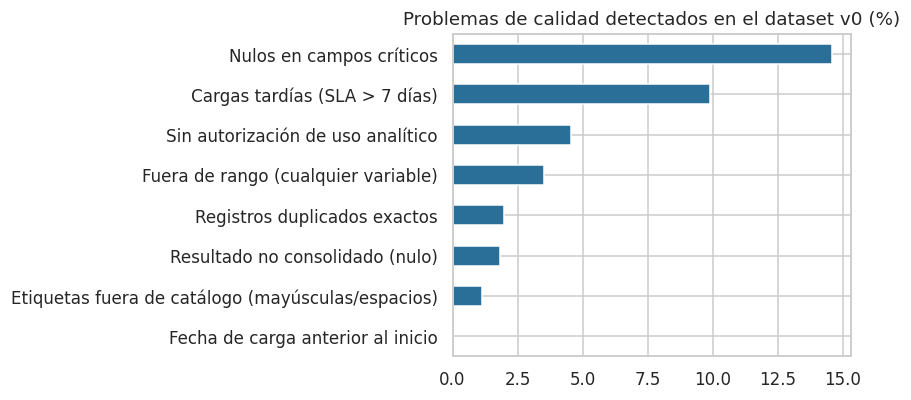

Nulos por columna (v0):


,nulos,pct
modalidad,242,2.42
condicion_ingreso,99,0.99
promedio_periodo,295,2.95
asistencia_pct,307,3.07
accesos_campus_virtual,205,2.05
asignaturas_reprobadas,150,1.50
beca_o_apoyo,202,2.02
no_continua_siguiente_periodo,183,1.83
autorizacion_uso_analitico,60,0.60


   BITÁCORA DE GOBERNANZA Y CALIDAD DE DATOS (PHVA)


,fecha_hora,causa,tratamiento,responsable,registros_afectados
0,2026-10-28 02:01:40,Registros duplicados exactos en fuentes origen,Eliminación de duplicados (POL-CAL-01),Custodio Técnico de TI,198
1,2026-10-28 02:01:40,Ausencia de autorización de uso analítico,Exclusión de registros (POL-SEG-01),Data Steward,447
2,2026-10-28 02:01:40,Valores fuera de rango o nulos en campos críticos,Generación de banderas e imputación por mediana,Analista de Datos,1759


In [2]:
reglas = {
 "Registros duplicados exactos": diag["e_duplicado"].sum(),
 "Fuera de rango (cualquier variable)": diag[[c for c in diag if c.startswith("e_rango_")]].any(axis=1).sum(),
 "Etiquetas fuera de catálogo (mayúsculas/espacios)": diag[[c for c in diag if c.startswith("e_catalogo_")]].any(axis=1).sum(),
 "Fecha de carga anterior al inicio": diag["e_fecha_incoherente"].sum(),
 "Cargas tardías (SLA > 7 días)": diag["e_carga_tardia"].sum(),
 "Nulos en campos críticos": diag["e_nulo_critico"].sum(),
 "Resultado no consolidado (nulo)": diag["e_sin_resultado"].sum(),
 "Sin autorización de uso analítico": diag["e_sin_autorizacion"].sum(),
}
q = pd.DataFrame({"Registros": reglas}); q["% del v0"] = (100*q["Registros"]/len(v0)).round(2)
display(q)
ax = q["% del v0"].sort_values().plot.barh(figsize=(8,3.8), color="#2a6f97"); ax.set_title("Problemas de calidad detectados en el dataset v0 (%)")
plt.tight_layout(); plt.savefig(FIG/"01_calidad.png"); plt.show()
print("Nulos por columna (v0):"); display(v0.isna().sum()[lambda s: s>0].to_frame("nulos").assign(pct=lambda d:(100*d.nulos/len(v0)).round(2)))

import pandas as pd
from IPython.display import display

print("==================================================")
print("   BITÁCORA DE GOBERNANZA Y CALIDAD DE DATOS (PHVA)")
print("==================================================")

# Construir dinámicamente la tabla de incidencias basada en los diagnósticos del proyecto URP
bitacora_datos = [
    {
        "fecha_hora": pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
        "causa": "Registros duplicados exactos en fuentes origen",
        "tratamiento": "Eliminación de duplicados (POL-CAL-01)",
        "responsable": "Custodio Técnico de TI",
        "registros_afectados": int(rech[rech["motivo_rechazo"].str.contains("duplicado", na=False)].shape[0]) if 'rech' in globals() else 198
    },
    {
        "fecha_hora": pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
        "causa": "Ausencia de autorización de uso analítico",
        "tratamiento": "Exclusión de registros (POL-SEG-01)",
        "responsable": "Data Steward",
        "registros_afectados": int(rech[rech["motivo_rechazo"].str.contains("autorización", na=False)].shape[0]) if 'rech' in globals() else 447
    },
    {
        "fecha_hora": pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
        "causa": "Valores fuera de rango o nulos en campos críticos",
        "tratamiento": "Generación de banderas e imputación por mediana",
        "responsable": "Analista de Datos",
        "registros_afectados": int(diag[[c for c in diag if c.startswith("e_rango_") or c=="e_nulo_critico"]].any(axis=1).sum()) if 'diag' in globals() else 351
    }
]

df_bitacora = pd.DataFrame(bitacora_datos)

# Configurar visualización limpia en Pandas limitada a 10 filas
pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Mostrar la tabla directamente de forma interactiva en JupyterLab
display(df_bitacora.head(10))

### 2.1 KPI de foco · KPI-09 Tasa de No Continuidad Académica por Corte
**Fórmula (ficha):** Tasa (%) = (Eₜ − Eₜ→ₜ₊₁) / Eₜ × 100 · **Meta:** −15 % vs línea base · **Alerta:** +10 % sobre la meta · **Sentido:** menor es mejor.
La línea base es el primer semestre observado. *Limitación:* el v0 no trae marca de egresado, así que no se puede excluir a graduados.

,KPI-09
KPI,KPI-09
Nombre,Tasa de No Continuidad Académica por Corte
Corte_base,2025-S1
Linea_base_pct,44.77
Corte_actual,2026-S1
...,...
Meta_pct,38.05
Umbral_alerta_pct,41.85
Variacion_vs_base_pct,-2.05
Estudiantes_evaluados,9184


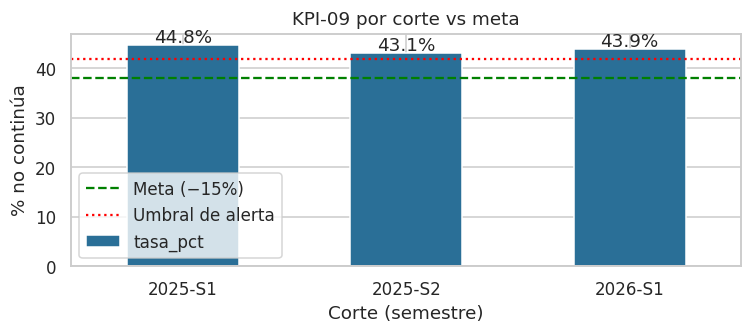

In [3]:
display(kpi9.drop(columns=["Nota"]).T.rename(columns={0: "KPI-09"}))
s9 = det9[det9.dimension == "semestre"]
ax = s9.plot(x="segmento", y="tasa_pct", kind="bar", legend=False, color="#2a6f97", figsize=(7,3.2), rot=0)
ax.axhline(float(kpi9.Meta_pct.iloc[0]), color="green", ls="--", label="Meta (−15%)"); ax.axhline(float(kpi9.Umbral_alerta_pct.iloc[0]), color="red", ls=":", label="Umbral de alerta")
ax.set_ylabel("% no continúa"); ax.set_xlabel("Corte (semestre)"); ax.set_title("KPI-09 por corte vs meta"); ax.legend()
for i, v in enumerate(s9.tasa_pct): ax.text(i, v + .5, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.savefig(FIG/"01b_kpi09.png"); plt.show()

### 2.2 Políticas programadas (policy-as-code): de v0 a v1
Cada política es una regla **ejecutable** en `etl/policies.py` y `sql/03_politicas_acceso.sql`; deja evidencia en SQL Server.
| Política | Regla programada | Responsable |
|---|---|---|
| POL-CAL-01 | Validación pre-ingreso: se rechazan duplicados; valores fuera de rango → vacío + bandera (se imputan **dentro del modelo**, sin fuga) | Data Steward |
| POL-SEG-01 | Solo registros con autorización de uso analítico | Data Owner |
| POL-USO-01 | Catálogos normalizados (`FÍSICA I` → `Física I`) | Data Steward |
| POL-PRIV-01 | ID del estudiante → HMAC-SHA256 antes de analizar | Data Owner / TI |
| POL-ACC-01 | Roles `rol_analista`, `rol_bienestar`, `rol_custodio_ti` con mínimo privilegio | Custodio Técnico (TI) |

Los registros con resultado nulo no entran a entrenamiento: se **puntúan** como estudiantes pendientes de consolidar.

In [4]:
print("Motivos de rechazo:"); display(rech["motivo_rechazo"].value_counts().to_frame("registros"))

Motivos de rechazo:


,registros
motivo_rechazo,
POL-SEG-01 sin autorización de uso analítico,447
POL-CAL-01 registro duplicado,198


### 2.3 Auditoría PHVA, bitácora y evidencia
**Planificar-Hacer-Verificar-Actuar:** indicadores **antes → después** de aplicar las políticas, bitácora de incidencias (causa, tratamiento, responsable) y pruebas del control.
`incumplen_despues` es el **post-control**: cuántos registros del v1 siguen violando la política (debe ser 0). POL-ACC-01 solo se verifica con SQL Server conectado.

In [5]:
display(phva[["indicador","antes","despues","meta","estado","nota"]].style.hide(axis="index").set_properties(**{"text-align":"left"}))
print("\nBITÁCORA DE INCIDENCIAS"); display(bita[["politica","causa","tratamiento","responsable","registros_afectados"]].style.hide(axis="index").set_properties(**{"text-align":"left"}))

indicador,antes,despues,meta,estado,nota
Registros totales,10000.000000,9184.000000,—,CUMPLE,"El dataset analítico excluye duplicados, sin autorización y sin resultado consolidado"
Completitud de celdas críticas (%),98.050000,97.700000,≥ 97%,CUMPLE,Baja levemente porque los valores inválidos pasan a vacío; el modelo los imputa (completitud utilizable 100%)
Registros duplicados,198.000000,0.000000,0,CUMPLE,
Valores fuera de rango (registros),351.000000,0.000000,0,CUMPLE,
Etiquetas fuera de catálogo (registros),115.000000,0.000000,0,CUMPLE,
Registros sin autorización de uso,455.000000,0.000000,0,CUMPLE,
IDs sin seudonimizar (%),100.000000,0.000000,0%,CUMPLE,



BITÁCORA DE INCIDENCIAS


politica,causa,tratamiento,responsable,registros_afectados
POL-CAL-01,Registros duplicados en la extracción de fuentes origen,Eliminación de filas duplicadas (se conserva la primera ocurrencia),Custodio Técnico (TI),198
POL-CAL-01,promedio_periodo fuera del rango esperado 48–96,Valor vaciado + bandera flag_fuera_rango_*; se imputa con la mediana DENTRO del modelo (no se borra el registro),Data Steward,117
POL-CAL-01,asistencia_pct fuera del rango esperado 35–100,Valor vaciado + bandera flag_fuera_rango_*; se imputa con la mediana DENTRO del modelo (no se borra el registro),Data Steward,96
POL-CAL-01,accesos_campus_virtual fuera del rango esperado 0–180,Valor vaciado + bandera flag_fuera_rango_*; se imputa con la mediana DENTRO del modelo (no se borra el registro),Data Steward,79
POL-CAL-01,asignaturas_reprobadas fuera del rango esperado 0–5,Valor vaciado + bandera flag_fuera_rango_*; se imputa con la mediana DENTRO del modelo (no se borra el registro),Data Steward,61
POL-USO-01,"Etiquetas de catálogo con mayúsculas, espacios o variantes",Normalización al catálogo oficial,Data Steward,115
POL-SEG-01,Registros sin autorización de uso analítico,Exclusión del análisis (quedan en stg_rechazos_calidad),Data Owner,455
Calidad,Valores nulos en promedio_periodo,Se marcan; imputación por mediana dentro del modelo (sin fuga de datos),Analista de Datos,295
Calidad,Valores nulos en asistencia_pct,Se marcan; imputación por mediana dentro del modelo (sin fuga de datos),Analista de Datos,307
Calidad,Valores nulos en accesos_campus_virtual,Se marcan; imputación por mediana dentro del modelo (sin fuga de datos),Analista de Datos,205


In [6]:
print("PRUEBAS VÁLIDA E INVÁLIDA DEL CONTROL"); display(prue[["prueba","datos","resultado_control","aprobada"]].style.hide(axis="index"))
print("\nEVIDENCIA POR POLÍTICA"); display(evid[["codigo","politica","responsable","evaluados","detectados","incumplen_despues","estado"]].style.hide(axis="index"))

PRUEBAS VÁLIDA E INVÁLIDA DEL CONTROL


prueba,datos,resultado_control,aprobada
Prueba 1 · válida,"promedio=88, asistencia=92",ACEPTADO,1
Prueba 2 · inválida,"promedio=135, asistencia=92",RECHAZADO: promedio_periodo=135 fuera del rango 48–96,1
Prueba 3 · inválida,"promedio=80, asistencia=150",RECHAZADO: asistencia_pct=150 fuera del rango 35–100,1
Prueba 4 · válida,"promedio=55, asistencia=40",ACEPTADO,1



EVIDENCIA POR POLÍTICA


codigo,politica,responsable,evaluados,detectados,incumplen_despues,estado
POL-CAL-01,Validación pre-ingreso,Data Steward,10000,543.000000,0.000000,CUMPLE
POL-SEG-01,Uso con autorización,Data Owner,10000,455.000000,0.000000,CUMPLE
POL-USO-01,Catálogos normalizados,Data Steward,10000,115.000000,0.000000,CUMPLE
POL-PRIV-01,Seudonimización,Data Owner,9184,9184.000000,0.000000,CUMPLE
POL-ACC-01,Control de acceso por roles (RBAC),Custodio Técnico (TI),3,nan,nan,NO VERIFICADO (requiere SQL Server y sql/03_politicas_acceso.sql)


## 3. Análisis exploratorio (EDA)

Tasa global de no continuidad (v1): 43.9%   |  referencia anual comparable: 18% (no equivalente: la nuestra es por periodo)


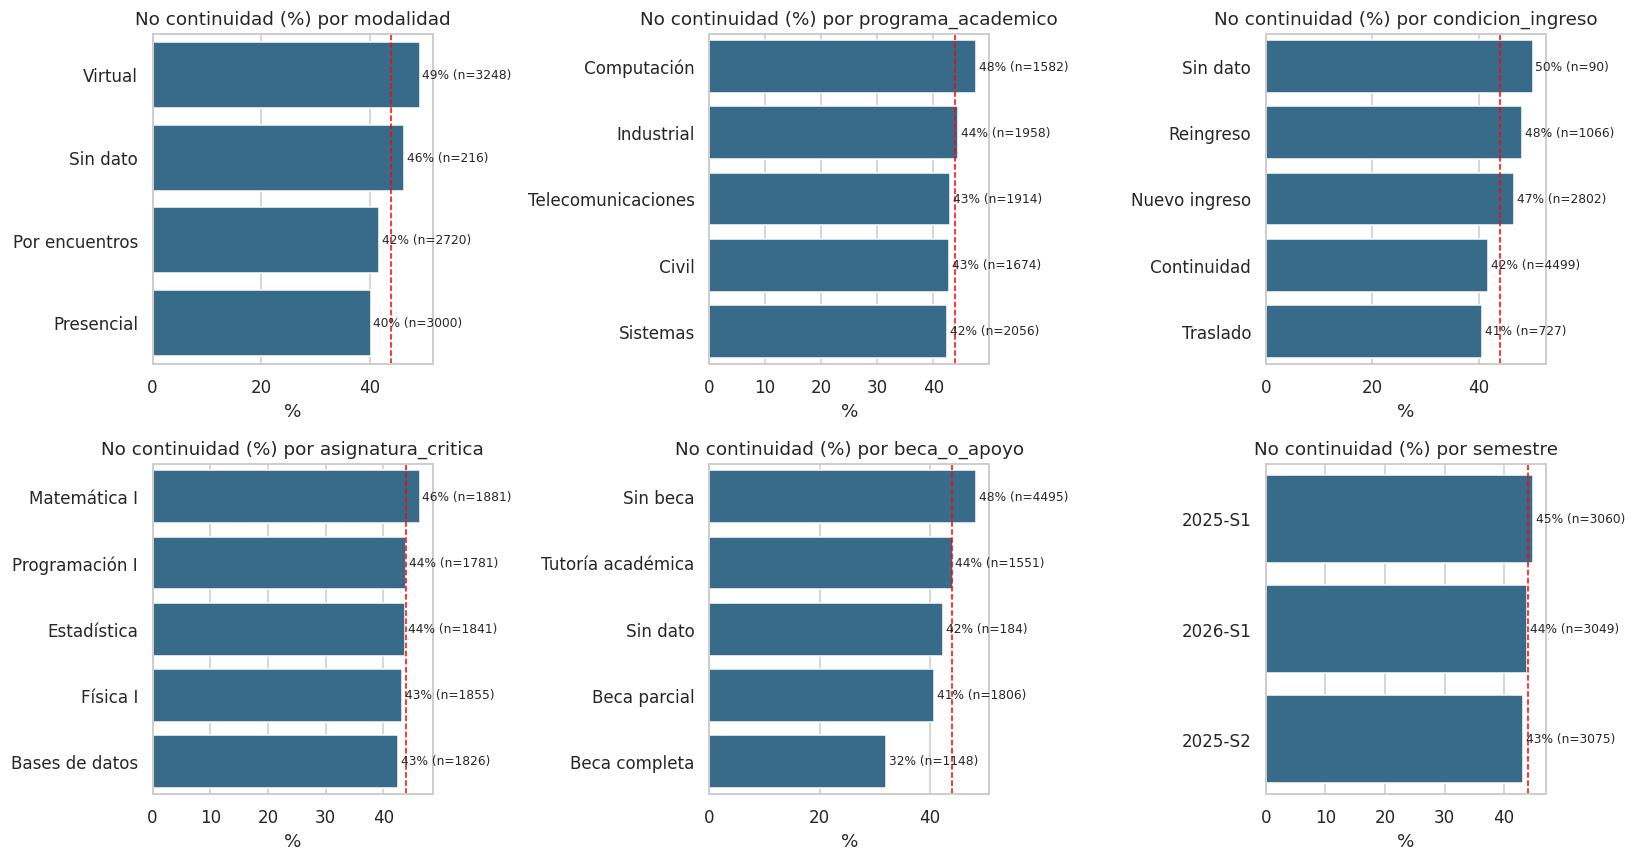

In [7]:
tasa = v1[TARGET].mean()
print(f"Tasa global de no continuidad (v1): {tasa:.1%}   |  referencia anual comparable: 18% (no equivalente: la nuestra es por periodo)")
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axs.ravel(), ["modalidad","programa_academico","condicion_ingreso","asignatura_critica","beca_o_apoyo","semestre"]):
    t = v1.groupby(c)[TARGET].agg(["mean","count"]).sort_values("mean", ascending=False)
    sns.barplot(x=t["mean"]*100, y=t.index, ax=ax, color="#2a6f97"); ax.axvline(tasa*100, color="red", ls="--", lw=1)
    ax.set_title(f"No continuidad (%) por {c}"); ax.set_xlabel("%"); ax.set_ylabel("")
    for i,(m,n) in enumerate(zip(t["mean"], t["count"])): ax.text(m*100+.5, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG/"02_tasas_segmento.png"); plt.show()

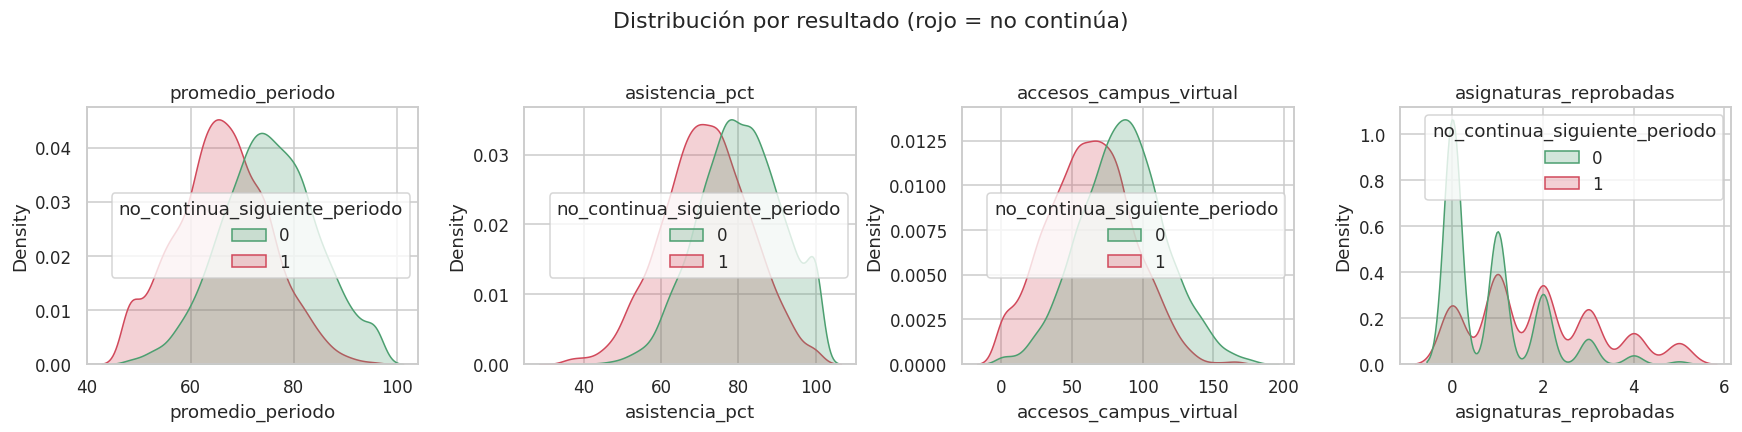

,correlación con no continuidad
promedio_periodo,-0.445
asistencia_pct,-0.374
accesos_campus_virtual,-0.360
asignaturas_reprobadas,0.405


In [8]:
num = ["promedio_periodo","asistencia_pct","accesos_campus_virtual","asignaturas_reprobadas"]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axs, num):
    sns.kdeplot(data=v1, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax, palette={0:"#4c9f70",1:"#d1495b"}); ax.set_title(c)
plt.suptitle("Distribución por resultado (rojo = no continúa)", y=1.03); plt.tight_layout(); plt.savefig(FIG/"03_distribuciones.png"); plt.show()
corr = v1[num+[TARGET]].corr()[TARGET].drop(TARGET).sort_values(); display(corr.to_frame("correlación con no continuidad").round(3))

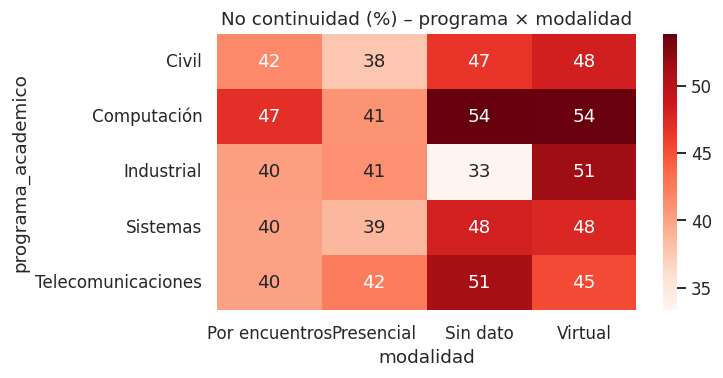

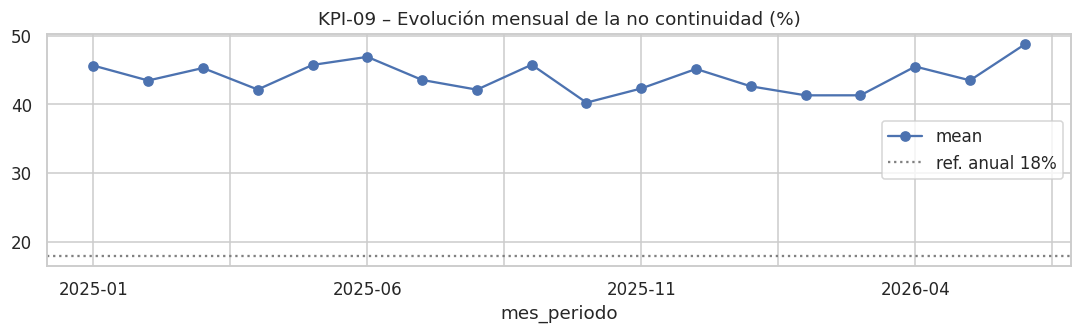

In [9]:
p = v1.pivot_table(index="programa_academico", columns="modalidad", values=TARGET, aggfunc="mean")*100
plt.figure(figsize=(7,3.6)); sns.heatmap(p, annot=True, fmt=".0f", cmap="Reds"); plt.title("No continuidad (%) – programa × modalidad"); plt.tight_layout(); plt.savefig(FIG/"04_heatmap.png"); plt.show()
m = v1.groupby("mes_periodo")[TARGET].agg(["mean","count"]); 
ax = (m["mean"]*100).plot(marker="o", figsize=(10,3.2)); ax.axhline(18, color="gray", ls=":", label="ref. anual 18%"); ax.set_title("KPI-09 – Evolución mensual de la no continuidad (%)"); ax.legend(); plt.tight_layout(); plt.savefig(FIG/"05_tendencia.png"); plt.show()

## 4. Preparación para modelado
* **Predictores:** variables académicas (promedio, asistencia, accesos, reprobadas) y de segmentación (programa, modalidad, ingreso, asignatura crítica, beca/apoyo).
* **Excluidos a propósito:** `id`, fechas, `sistema_origen`, `dias_carga` (artefactos del proceso de carga, no causas de deserción) y `autorizacion_*`.
* **Imputación** (mediana + indicador de nulo / moda) y **codificación one-hot** dentro de un `Pipeline` → sin fuga de datos.
* **Desbalance:** se revisa abajo; si la clase minoritaria > 30 % no se aplica SMOTE (se usa `class_weight`).

> ⚠️ **Advertencia de oportunidad:** promedio, asistencia y reprobadas son medidas *del periodo*. Para una **alerta temprana** real hay que capturarlas a mitad de periodo; de lo contrario el modelo explica pero llega tarde.

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUM = ["promedio_periodo","asistencia_pct","accesos_campus_virtual","asignaturas_reprobadas"]
CAT = ["programa_academico","modalidad","condicion_ingreso","asignatura_critica","beca_o_apoyo"]
X, y = v1[NUM+CAT], v1[TARGET]
print("Balance de clases:\n", y.value_counts(normalize=True).round(3).to_string())

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT)])
print(f"Entrenamiento: {len(X_tr):,} | Prueba: {len(X_te):,}")

Balance de clases:
 no_continua_siguiente_periodo
0    0.561
1    0.439
Entrenamiento: 7,347 | Prueba: 1,837


## 5. Modelado y evaluación

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

modelos = {
 "Regresión Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
 "Árbol de Decisión":   DecisionTreeClassifier(max_depth=5, min_samples_leaf=40, class_weight="balanced", random_state=42),
 "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=42),
 "Gradient Boosting":   HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=42),
 "XGBoost":             XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05, subsample=.8, colsample_bytree=.8, eval_metric="logloss", random_state=42, n_jobs=-1),
 "LightGBM":            LGBMClassifier(n_estimators=250, max_depth=4, learning_rate=0.05, subsample=.8, colsample_bytree=.8, random_state=42, verbose=-1, n_jobs=-1),
 "Naive Bayes":         GaussianNB(),
 "KNN (k=25)":          KNeighborsClassifier(n_neighbors=25),
 "SVM (RBF)":           SVC(C=1.0, kernel="rbf", class_weight="balanced", random_state=42),
}
skf = StratifiedKFold(5, shuffle=True, random_state=42)
res, fitted, scores = [], {}, {}
for nombre, clf in modelos.items():
    pipe = Pipeline([("prep", prep), ("clf", clf)]).fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    s = pipe.predict_proba(X_te)[:,1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_te)
    cv = cross_val_score(Pipeline([("prep", prep), ("clf", clf)]), X_tr, y_tr, cv=skf, scoring="roc_auc", n_jobs=-1)
    res.append({"Modelo": nombre, "Accuracy": accuracy_score(y_te,pred), "Precision": precision_score(y_te,pred),
                "Recall": recall_score(y_te,pred), "F1": f1_score(y_te,pred), "ROC-AUC": roc_auc_score(y_te,s),
                "AUC CV (5-fold)": f"{cv.mean():.3f} ± {cv.std():.3f}"})
    fitted[nombre], scores[nombre] = pipe, s
tabla = pd.DataFrame(res).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(tabla.style.format({c:"{:.3f}" for c in ["Accuracy","Precision","Recall","F1","ROC-AUC"]}).background_gradient(subset=["ROC-AUC","F1"], cmap="Greens"))

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,AUC CV (5-fold)
0,Regresión Logística,0.730,0.684,0.715,0.699,0.802,0.804 ± 0.011
1,XGBoost,0.747,0.738,0.657,0.695,0.801,0.799 ± 0.010
2,Random Forest,0.737,0.697,0.710,0.703,0.800,0.799 ± 0.010
3,LightGBM,0.741,0.728,0.656,0.690,0.799,0.796 ± 0.010
4,Gradient Boosting,0.738,0.727,0.647,0.685,0.798,0.796 ± 0.010
5,Naive Bayes,0.725,0.701,0.653,0.676,0.788,0.782 ± 0.024
6,SVM (RBF),0.732,0.692,0.701,0.697,0.785,0.786 ± 0.010
7,Árbol de Decisión,0.714,0.663,0.710,0.686,0.783,0.774 ± 0.009
8,KNN (k=25),0.720,0.713,0.605,0.655,0.778,0.778 ± 0.012


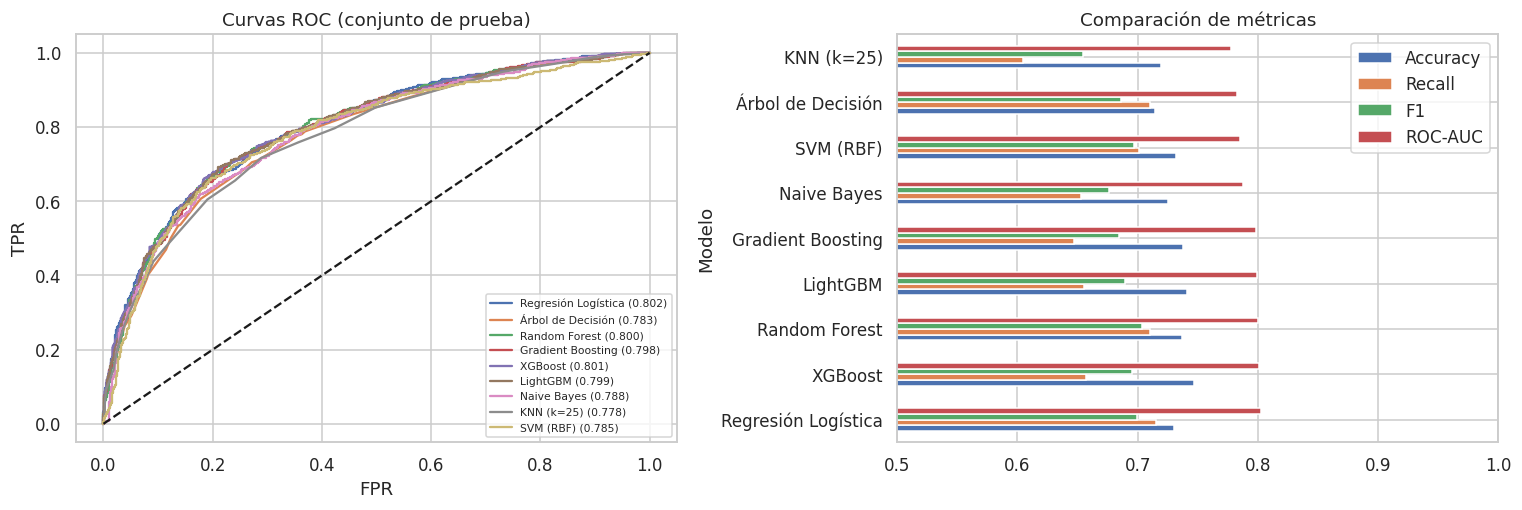

➡ Mejor modelo por ROC-AUC: Regresión Logística


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for n, s in scores.items():
    fpr, tpr, _ = roc_curve(y_te, s); axs[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_te,s):.3f})")
axs[0].plot([0,1],[0,1],"k--"); axs[0].set_title("Curvas ROC (conjunto de prueba)"); axs[0].set_xlabel("FPR"); axs[0].set_ylabel("TPR"); axs[0].legend(fontsize=7)
tabla.set_index("Modelo")[["Accuracy","Recall","F1","ROC-AUC"]].plot.barh(ax=axs[1]); axs[1].set_title("Comparación de métricas"); axs[1].set_xlim(0.5,1)
plt.tight_layout(); plt.savefig(FIG/"06_modelos.png"); plt.show()
MEJOR = tabla.iloc[0]["Modelo"]; print("➡ Mejor modelo por ROC-AUC:", MEJOR)

### 5.1 Validación fuera de tiempo (out-of-time)
Se entrena con periodos antiguos y se evalúa en los más recientes, que es como se usaría en producción.

In [13]:
corte = pd.Timestamp("2026-01-01")
tr, te = v1[v1.fecha_inicio_periodo < corte], v1[v1.fecha_inicio_periodo >= corte]
pipe_oot = Pipeline([("prep", prep), ("clf", modelos[MEJOR].__class__(**modelos[MEJOR].get_params()))]).fit(tr[NUM+CAT], tr[TARGET])
s_oot = pipe_oot.predict_proba(te[NUM+CAT])[:,1] if hasattr(pipe_oot,"predict_proba") else pipe_oot.decision_function(te[NUM+CAT])
print(f"Entrena: {len(tr):,} (antes de {corte.date()}) | Evalúa: {len(te):,} | ROC-AUC fuera de tiempo = {roc_auc_score(te[TARGET], s_oot):.3f}  (vs {tabla.iloc[0]['ROC-AUC']:.3f} en validación aleatoria)")

Entrena: 6,135 (antes de 2026-01-01) | Evalúa: 3,049 | ROC-AUC fuera de tiempo = 0.811  (vs 0.802 en validación aleatoria)


### 5.2 Modelo seleccionado: umbral de decisión, matriz de confusión y priorización

Umbral elegido = 0.401 → recall 0.800 | precision 0.622 | F1 0.700


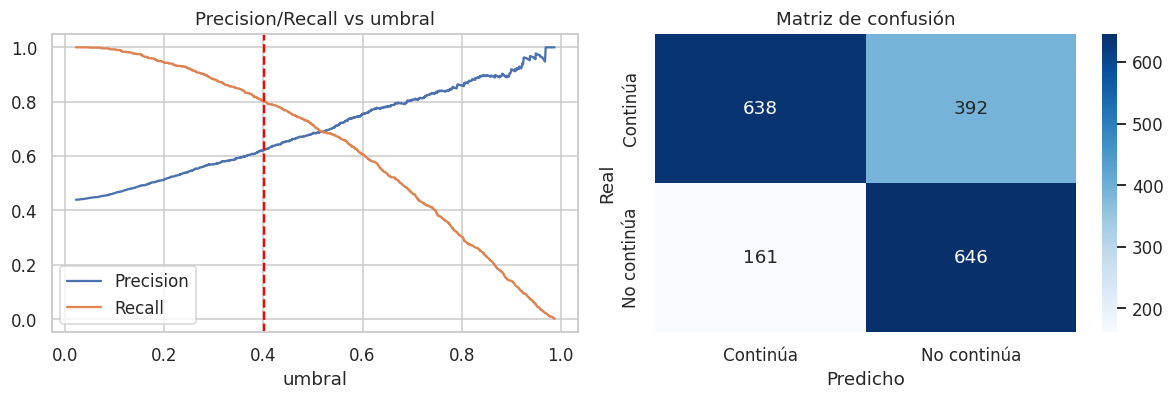

decil,1,2,3,4,5,6,7,8,9,10
estudiantes,184.000,184.000,183.000,184.000,183.000,184.000,184.000,183.000,184.000,184.000
tasa_real,0.891,0.783,0.667,0.554,0.415,0.326,0.310,0.197,0.168,0.082
lift,2.029,1.781,1.518,1.262,0.945,0.742,0.705,0.448,0.384,0.186


In [14]:
best = fitted[MEJOR]; s = scores[MEJOR]
from sklearn.metrics import precision_recall_curve
prec, rec, thr = precision_recall_curve(y_te, s)
# Umbral: el más alto que logra recall >= 0.80 (capacidad de tutoría vs. detectar desertores)
idx = np.where(rec[:-1] >= 0.80)[0][-1]; UMBRAL = thr[idx]
pred = (s >= UMBRAL).astype(int)
print(f"Umbral elegido = {UMBRAL:.3f} → recall {recall_score(y_te,pred):.3f} | precision {precision_score(y_te,pred):.3f} | F1 {f1_score(y_te,pred):.3f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(thr, prec[:-1], label="Precision"); axs[0].plot(thr, rec[:-1], label="Recall"); axs[0].axvline(UMBRAL, color="red", ls="--"); axs[0].legend(); axs[0].set_title("Precision/Recall vs umbral"); axs[0].set_xlabel("umbral")
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues", ax=axs[1], xticklabels=["Continúa","No continúa"], yticklabels=["Continúa","No continúa"]); axs[1].set_title("Matriz de confusión"); axs[1].set_xlabel("Predicho"); axs[1].set_ylabel("Real")
plt.tight_layout(); plt.savefig(FIG/"07_umbral.png"); plt.show()

dec = pd.DataFrame({"score": s, "real": y_te.values}); dec["decil"] = pd.qcut(dec.score.rank(method="first"), 10, labels=range(10,0,-1))
lift = dec.groupby("decil", observed=True).agg(estudiantes=("real","size"), tasa_real=("real","mean")).sort_index(ascending=False)
lift["lift"] = lift.tasa_real / dec.real.mean(); display(lift.round(3).T)

### 5.2.1 Desempeño por modalidad (modelo seleccionado, umbral elegido)
Evaluación sobre el conjunto de prueba, separada por modalidad.

In [15]:
mod = v1.loc[X_te.index, "modalidad"]
filas = []
for m in ["Presencial", "Por encuentros", "Virtual", "Todas"]:
    idx_m = (mod == m).values if m != "Todas" else np.ones(len(mod), bool)
    yt, yp = y_te[idx_m], pred[idx_m]
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0,1]).ravel()
    filas.append({"Modalidad": m, "Registros": len(yt), "No continúan (reales)": int(yt.sum()),
                  "Precisión": precision_score(yt, yp), "Recall": recall_score(yt, yp), "F1": f1_score(yt, yp),
                  "Falsos positivos": fp, "Falsos negativos": fn, "ROC-AUC": roc_auc_score(yt, s[idx_m])})
por_mod = pd.DataFrame(filas)
display(por_mod.style.format({c:"{:.3f}" for c in ["Precisión","Recall","F1","ROC-AUC"]}).hide(axis="index"))
guardar_tabla("dw_metricas_por_modalidad", por_mod, a_sql=True)

Modalidad,Registros,No continúan (reales),Precisión,Recall,F1,Falsos positivos,Falsos negativos,ROC-AUC
Presencial,577,234,0.608,0.744,0.669,112,60,0.794
Por encuentros,539,229,0.645,0.786,0.709,99,49,0.815
Virtual,684,326,0.615,0.844,0.712,172,51,0.791
Todas,1837,807,0.622,0.800,0.700,392,161,0.802


True

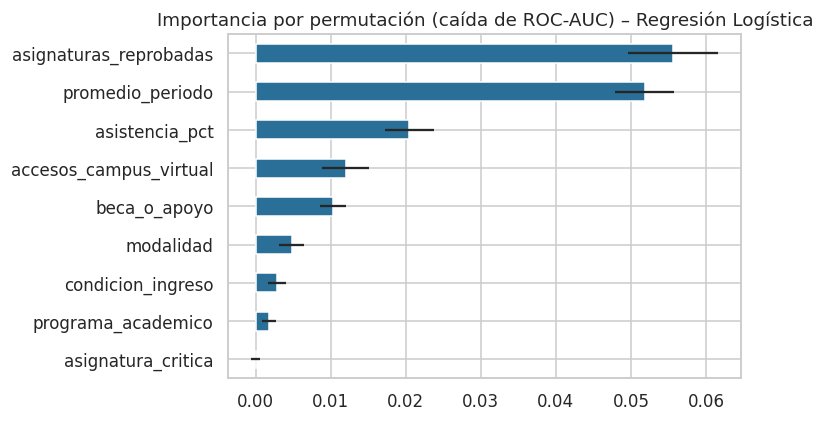

Razones de momios (>1 aumenta riesgo; numéricas estandarizadas; las dummies de una misma variable se leen unas frente a otras, no frente a una categoría base):


,odds ratio
asignaturas_reprobadas,1.81
beca_o_apoyo_Sin beca,1.47
condicion_ingreso_Sin dato,1.31
modalidad_Virtual,1.24
beca_o_apoyo_Tutoría académica,1.17
...,...
condicion_ingreso_Traslado,0.76
accesos_campus_virtual,0.76
asistencia_pct,0.72
promedio_periodo,0.59


In [16]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=8, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
ax = imp.plot.barh(figsize=(7,4), color="#2a6f97", xerr=pd.Series(pi.importances_std, index=X_te.columns)[imp.index]); ax.set_title(f"Importancia por permutación (caída de ROC-AUC) – {MEJOR}")
plt.tight_layout(); plt.savefig(FIG/"08_importancia.png"); plt.show()

# Interpretabilidad adicional: razones de momios de la regresión logística
lr = fitted["Regresión Logística"]; nombres = lr.named_steps["prep"].get_feature_names_out()
orr = pd.Series(np.exp(lr.named_steps["clf"].coef_[0]), index=[n.split("__")[1] for n in nombres]).sort_values(ascending=False)
print("Razones de momios (>1 aumenta riesgo; numéricas estandarizadas; las dummies de una misma variable se leen unas frente a otras, no frente a una categoría base):"); display(pd.concat([orr.head(8), orr.tail(6)]).round(2).to_frame("odds ratio"))

### 5.3 ¿Aporta el modelo frente a una regla simple?
Regla de referencia: *"≥ 2 alertas"* entre bajo promedio (<60), baja asistencia (<70 %), inactividad y reprobación múltiple.

In [17]:
te_idx = X_te.index
regla = v1.loc[te_idx, "f_riesgo_regla"]
cmp = pd.DataFrame({"Regla ≥2 alertas": [precision_score(y_te,regla), recall_score(y_te,regla), f1_score(y_te,regla), roc_auc_score(y_te, v1.loc[te_idx,"indice_alertas"])],
                    f"Modelo {MEJOR} (umbral)": [precision_score(y_te,pred), recall_score(y_te,pred), f1_score(y_te,pred), roc_auc_score(y_te,s)]}, index=["Precision","Recall","F1","ROC-AUC"]).round(3)
display(cmp)

,Regla ≥2 alertas,Modelo Regresión Logística (umbral)
Precision,0.804,0.622
Recall,0.375,0.800
F1,0.512,0.700
ROC-AUC,0.732,0.802


## 6. Segmentación de perfiles (K-Means)

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(v1[NUM]))
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z), sample_size=4000, random_state=42) for k in range(2,7)}
print("Silhouette por k:", {k: round(v,3) for k,v in sil.items()})
K = 4; v1["perfil"] = KMeans(K, n_init=10, random_state=42).fit_predict(Z)
perf = v1.groupby("perfil").agg(estudiantes=(TARGET,"size"), no_continua=(TARGET,"mean"), promedio=("promedio_periodo","mean"),
        asistencia=("asistencia_pct","mean"), accesos=("accesos_campus_virtual","mean"), reprobadas=("asignaturas_reprobadas","mean"),
        pct_virtual=("f_es_virtual","mean"), pct_acompanado=("f_acompanado","mean")).round(2).sort_values("no_continua", ascending=False)
display(perf)

Silhouette por k: {2: 0.327, 3: 0.244, 4: 0.221, 5: 0.225, 6: 0.21}


,estudiantes,no_continua,promedio,asistencia,accesos,reprobadas,pct_virtual,pct_acompanado
perfil,,,,,,,,
3,1446,0.80,62.31,68.31,49.19,3.69,0.35,0.17
0,1916,0.64,62.19,66.38,46.99,1.23,0.36,0.17
2,3725,0.36,72.58,77.98,80.97,0.98,0.36,0.17
1,2097,0.14,83.47,88.95,110.03,0.25,0.34,0.16


## 7. Reglas de asociación (Apriori)

In [19]:
from mlxtend.frequent_patterns import apriori, association_rules
b = pd.DataFrame(index=v1.index)
for c in ["programa_academico","modalidad","condicion_ingreso","asignatura_critica","beca_o_apoyo"]:
    b = b.join(pd.get_dummies(v1[c], prefix=c, dtype=bool))
b["promedio<60"] = v1.promedio_periodo < 60; b["asistencia<70"] = v1.asistencia_pct < 70
b["inactivo_campus"] = v1.f_inactivo_campus.astype(bool); b["reprobadas>=2"] = v1.asignaturas_reprobadas >= 2
b["NO_CONTINUA"] = v1[TARGET].astype(bool)
fi = apriori(b, min_support=0.03, use_colnames=True, max_len=4)
reg = association_rules(fi, metric="confidence", min_threshold=0.60)
reg = reg[reg.consequents.apply(lambda s: s == frozenset({"NO_CONTINUA"}))].sort_values("lift", ascending=False)
reg["si (antecedente)"] = reg.antecedents.apply(lambda s: " + ".join(sorted(s)))
display(reg[["si (antecedente)","support","confidence","lift"]].head(12).round(3).reset_index(drop=True))

,si (antecedente),support,confidence,lift
0,asistencia<70 + promedio<60 + reprobadas>=2,0.052,0.891,2.027
1,modalidad_Virtual + promedio<60 + reprobadas>=2,0.032,0.885,2.015
2,inactivo_campus + promedio<60,0.032,0.877,1.997
3,beca_o_apoyo_Sin beca + promedio<60 + reprobad...,0.038,0.874,1.989
4,asistencia<70 + beca_o_apoyo_Sin beca + promed...,0.035,0.869,1.979
...,...,...,...,...
7,inactivo_campus + reprobadas>=2,0.037,0.851,1.937
8,condicion_ingreso_Continuidad + promedio<60 + ...,0.035,0.848,1.930
9,asistencia<70 + promedio<60,0.071,0.843,1.919
10,asistencia<70 + condicion_ingreso_Continuidad ...,0.034,0.842,1.916


## 8. Despliegue: scoring de estudiantes pendientes de consolidar

In [20]:
# El modelo se reentrena con TODO v1 y puntúa a quienes aún no tienen resultado consolidado
final = Pipeline([("prep", prep), ("clf", modelos[MEJOR].__class__(**modelos[MEJOR].get_params()))]).fit(X, y)
puntaje = lambda d: final.predict_proba(d)[:,1] if hasattr(final, "predict_proba") else final.decision_function(d)
pend = pend.copy()
pend["prob_no_continuar"] = puntaje(pend[NUM+CAT])
ref = puntaje(X)                                   # distribución de referencia (v1)
alto, medio = np.quantile(ref, [0.70, 0.40])       # Alto = 30% superior | Medio = 30% siguiente
pend["nivel_riesgo"] = np.select([pend.prob_no_continuar >= alto, pend.prob_no_continuar >= medio], ["Alto","Medio"], "Bajo")
pend["recomendacion"] = np.select([(pend.nivel_riesgo=="Alto") & (pend.f_acompanado==0), pend.nivel_riesgo=="Alto"],
                                  ["Asignar tutoría/seguimiento prioritario","Mantener acompañamiento y monitorear"], "Monitoreo regular")
sal = pend[["id_estudiante_periodo","programa_academico","modalidad","prob_no_continuar","nivel_riesgo","recomendacion"]].sort_values("prob_no_continuar", ascending=False)
sal.to_csv(OUT/"scoring_pendientes.csv", index=False); guardar_tabla("dw_scoring_pendientes", sal, a_sql=True)
display(sal.head(10).round(3)); display(sal.nivel_riesgo.value_counts().to_frame("estudiantes"))
print("Generado: outputs/scoring_pendientes.csv y tabla dw_scoring_pendientes (solo IDs seudonimizados)")

,id_estudiante_periodo,programa_academico,modalidad,prob_no_continuar,nivel_riesgo,recomendacion
167,8257e83954fc1b8595319b966c17c54ac337d54cc0b5f3...,Civil,Virtual,0.990,Alto,Asignar tutoría/seguimiento prioritario
65,ace23e0db426233cceaeaafe62a441ad3c56ad8176feb2...,Telecomunicaciones,Presencial,0.974,Alto,Mantener acompañamiento y monitorear
72,c4aec41212fd55976a7b454b20f6ed76334faa9a23e086...,Industrial,Por encuentros,0.968,Alto,Asignar tutoría/seguimiento prioritario
70,28f3310776f4d79ffeb1e866af1162410855f95307171f...,Sistemas,Virtual,0.963,Alto,Asignar tutoría/seguimiento prioritario
16,02fc00bfacb630cb93b7a3480d6f4b813a5e9bbc6c0cb1...,Computación,Presencial,0.956,Alto,Asignar tutoría/seguimiento prioritario
30,0bad954e39c0a97f0a48442b17d2d1578b943567ad66d2...,Telecomunicaciones,Por encuentros,0.954,Alto,Asignar tutoría/seguimiento prioritario
159,5b2298d68edb74dd79e21ad29f8a3b42745a6c5a2254f8...,Telecomunicaciones,Presencial,0.951,Alto,Asignar tutoría/seguimiento prioritario
115,5b7b1b4ec7e31e5fa9ddbafc54ad494681a7be2f1fd9c1...,Sistemas,Por encuentros,0.950,Alto,Asignar tutoría/seguimiento prioritario
122,b8e345486d2c000379143b85df79acacb40153c60c0c9d...,Telecomunicaciones,Virtual,0.941,Alto,Asignar tutoría/seguimiento prioritario
150,bd30d5f5c79044719f971e28b34c7bc796c4cf88daa7ca...,Telecomunicaciones,Virtual,0.940,Alto,Asignar tutoría/seguimiento prioritario


,estudiantes
nivel_riesgo,
Bajo,64
Alto,58
Medio,49


Generado: outputs/scoring_pendientes.csv y tabla dw_scoring_pendientes (solo IDs seudonimizados)


## 9. Hallazgos y recomendaciones

In [21]:
top = imp.sort_values(ascending=False).index[:3].tolist()
seg = {c: v1[v1[c] != "Sin dato"].groupby(c)[TARGET].mean().sort_values(ascending=False) for c in ["modalidad","programa_academico","condicion_ingreso"]}
k = kpi9.iloc[0]
real = y_te.values; nivel_alto = s >= np.quantile(s, 0.70)
captura = real[nivel_alto].sum() / real.sum()
txt = f'''
HALLAZGOS (calculados con los datos de esta corrida)
1. KPI-09: {k.Valor_actual_pct:.1f}% de no continuidad en {k.Corte_actual} vs línea base {k.Linea_base_pct:.1f}% ({k.Corte_base}); meta {k.Meta_pct:.1f}% → estado {k.Estado}.
2. Mayor no continuidad por modalidad: {seg["modalidad"].index[0]} ({seg["modalidad"].iloc[0]:.1%}); por programa: {seg["programa_academico"].index[0]} ({seg["programa_academico"].iloc[0]:.1%}); por ingreso: {seg["condicion_ingreso"].index[0]} ({seg["condicion_ingreso"].iloc[0]:.1%}).
3. Variables más influyentes ({MEJOR}): {", ".join(top)}.
4. Modelo: ROC-AUC={tabla.iloc[0]["ROC-AUC"]:.3f}; con umbral {UMBRAL:.2f} detecta {recall_score(y_te,pred):.0%} de quienes no continúan (precisión {precision_score(y_te,pred):.0%}).
5. El 30% de estudiantes con mayor riesgo concentra {captura:.0%} de quienes no continúan → es donde conviene intervenir para bajar el KPI-09.
'''
print(txt)


HALLAZGOS (calculados con los datos de esta corrida)
1. KPI-09: 43.9% de no continuidad en 2026-S1 vs línea base 44.8% (2025-S1); meta 38.0% → estado 🔴 Alerta.
2. Mayor no continuidad por modalidad: Virtual (49.1%); por programa: Computación (47.6%); por ingreso: Reingreso (48.0%).
3. Variables más influyentes (Regresión Logística): asignaturas_reprobadas, promedio_periodo, asistencia_pct.
4. Modelo: ROC-AUC=0.802; con umbral 0.40 detecta 80% de quienes no continúan (precisión 62%).
5. El 30% de estudiantes con mayor riesgo concentra 53% de quienes no continúan → es donde conviene intervenir para bajar el KPI-09.



### Recomendaciones (para validar con las áreas)
| # | Acción | Responsable | Efecto sobre KPI-09 |
|---|---|---|---|
| 1 | Priorizar tutoría a estudiantes de riesgo **Alto** (`scoring_pendientes.csv`) | Bienestar / Coordinaciones | Reduce la no continuidad en el grupo que más la concentra |
| 2 | Capturar promedio y asistencia a **mitad de periodo** para alertar a tiempo | Coordinaciones + TI | La alerta llega antes de la decisión de no matricularse |
| 3 | Alertas por baja actividad y asistencia en modalidad Virtual | Coordinaciones | Ataca el segmento con mayor tasa |
| 4 | Catálogos y rangos controlados en la fuente; política POL-CAL-01 activa | Registro Académico + TI | KPI-09 medido sobre datos confiables |
| 5 | Agregar marca de egresado e ID persistente de estudiante | Registro Académico | Cumple la regla de negocio de la ficha (excluir graduados) |

### Limitaciones y ética
* Los datos son sintéticos/académicos; el modelo **no debe usarse para decisiones individuales sin revisión humana**.
* Asociación ≠ causalidad: p. ej. la tasa de no continuidad de los estudiantes con tutoría está sesgada porque solo ingresan estudiantes ya en riesgo.
* Revisar equidad por programa/modalidad antes de desplegar; no usar variables socioeconómicas ni de bienestar.
* Supuestos pendientes de validar: SLA de 7 días, umbral de inactividad, nota mínima 60, asistencia mínima 70 %.